In [ ]:
import csv
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.renderings import (
    render_pointcloud,
)
from IPython.display import display, SVG
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter, MaxNLocator


COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}

datadir = Path("../../data/")

In [ ]:
def load_localization_points(csv_path, names, *, probe_map=None, coordinate_scale=1.0):
    """Read x,y,z,probe columns and return (points_by_protein, resolved_probe_map).

    Without probe_map, names are assigned to distinct probes in first-appearance
    order, reproducing the original Polars partition_by('probe')/zip logic.
    The number of distinct probes must then equal len(names).
    An explicit map is {protein_name: probe_value}; values compare as strings.
    With an explicit map, other probes are ignored. coordinate_scale converts
    XYZ to micrometers: 1.0 for um, 0.001 for nm. No axes are swapped or shifted.
    """
    names = tuple(names)
    if not names or len(set(names)) != len(names):
        raise ValueError("names must be nonempty and distinct.")
    if not np.isfinite(coordinate_scale) or coordinate_scale <= 0:
        raise ValueError("coordinate_scale must be positive.")
    if probe_map is not None:
        if set(probe_map) != set(names):
            raise ValueError("probe_map must contain exactly the entries in names.")
        probe_map = {name: str(probe_map[name]) for name in names}
        if len(set(probe_map.values())) != len(names):
            raise ValueError("Each protein must be assigned a distinct probe.")
        selected = set(probe_map.values())
    else:
        selected = None
    groups = {}
    with Path(csv_path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        missing = {"x", "y", "z", "probe"} - set(reader.fieldnames or [])
        if missing:
            raise ValueError(f"CSV is missing columns: {sorted(missing)}.")
        for line, row in enumerate(reader, start=2):
            probe = row["probe"]
            if selected is not None and probe not in selected:
                continue
            try:
                xyz = tuple(float(row[axis]) * coordinate_scale for axis in "xyz")
            except (ValueError, TypeError) as error:
                raise ValueError(
                    f"Invalid XYZ coordinates at CSV row {line}."
                ) from error
            if not np.isfinite(xyz).all():
                raise ValueError(f"Nonfinite XYZ coordinates at CSV row {line}.")
            groups.setdefault(probe, []).append(xyz)
    if probe_map is None:
        if len(groups) != len(names):
            raise ValueError(
                f"Found probes {list(groups)}, but received {len(names)} names. "
                "Supply probe_map to select channels explicitly."
            )
        probe_map = dict(zip(names, groups))
    points = {}
    for name in names:
        probe = probe_map[name]
        if probe not in groups:
            raise ValueError(f"Probe {probe!r} assigned to {name!r} was not found.")
        points[name] = np.asarray(groups[probe], dtype=float)
    return points, probe_map


def square_bounds(x0s, y0s, side=4.0):
    """ROI array with rows (xmin,xmax,ymin,ymax), in micrometers.

    Each supplied (x0,y0) is the square's lower-left corner; no BoundingSquare
    class is required. The two coordinate lists must have equal lengths.
    """
    x, y = np.asarray(x0s, dtype=float), np.asarray(y0s, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or x.shape != y.shape or x.size == 0:
        raise ValueError("x0s and y0s must be nonempty 1D arrays of equal length.")
    if (
        not np.isfinite(x).all()
        or not np.isfinite(y).all()
        or not np.isfinite(side)
        or side <= 0
    ):
        raise ValueError("ROI origins must be finite and side must be positive.")
    return np.column_stack((x, x + side, y, y + side))


@dataclass
class RenderedROIOverview:
    image: np.ndarray
    extent: tuple
    squares: np.ndarray
    colors: dict
    point_counts: dict
    probe_map: dict


def render_roi_overview(
    points,
    squares,
    render_pointcloud,
    *,
    colors=None,
    height_px=700,
    opacity=0.2,
    point_size=None,
    padding=0.03,
    anti_aliasing=None,
    probe_map=None,
):
    """Render both channels together in an orthographic XY view.

    Frame bounds include ALL localizations and ALL squares, with padding on
    each side as a fraction of the unpadded width/height. XYZ arrays are passed
    unchanged to the helper. ROI outlines are added later in Matplotlib.
    point_size=None omits that argument, preserving the helper's default.
    height_px controls raster resolution. If the helper uses pixel-sized
    points, increasing height_px also makes them smaller relative to the scene
    unless point_size is increased. Gaussian helpers may scale differently.
    """
    import pyvista as pv

    colors = {**COLOR_DICT, **(colors or {})}
    arrays = {name: np.asarray(xyz, dtype=float) for name, xyz in points.items()}
    if not arrays:
        raise ValueError("At least one point cloud is required.")
    for name, xyz in arrays.items():
        if (
            xyz.ndim != 2
            or xyz.shape[1] != 3
            or len(xyz) == 0
            or not np.isfinite(xyz).all()
        ):
            raise ValueError(
                f"{name} must be a nonempty finite (N,3) coordinate array."
            )
    squares = np.asarray(squares, dtype=float)
    if (
        squares.ndim != 2
        or squares.shape[1] != 4
        or len(squares) == 0
        or not np.isfinite(squares).all()
        or np.any(squares[:, 1::2] <= squares[:, ::2])
    ):
        raise ValueError(
            "squares must contain increasing (xmin,xmax,ymin,ymax) bounds."
        )
    if not np.isfinite(padding) or padding < 0:
        raise ValueError("padding must be nonnegative.")
    if not np.isfinite(opacity) or not 0 <= opacity <= 1:
        raise ValueError("opacity must lie between 0 and 1.")
    height_px = int(height_px)
    if height_px < 2:
        raise ValueError("height_px must be at least 2.")
    if point_size is not None and (not np.isfinite(point_size) or point_size <= 0):
        raise ValueError("point_size must be positive or None.")

    lows = np.min([xyz.min(axis=0) for xyz in arrays.values()], axis=0)
    highs = np.max([xyz.max(axis=0) for xyz in arrays.values()], axis=0)
    x0, y0 = np.minimum(lows[:2], squares[:, [0, 2]].min(axis=0))
    x1, y1 = np.maximum(highs[:2], squares[:, [1, 3]].max(axis=0))
    dx, dy = x1 - x0, y1 - y0
    x0, x1 = x0 - padding * dx, x1 + padding * dx
    y0, y1 = y0 - padding * dy, y1 + padding * dy
    dx, dy = x1 - x0, y1 - y0
    width_px = max(2, int(np.ceil(height_px * dx / dy)))
    cx, cy, cz = (x0 + x1) / 2, (y0 + y1) / 2, (lows[2] + highs[2]) / 2
    distance = 2 * max(dx, dy, highs[2] - lows[2])
    half_width = dy / 2 * width_px / height_px
    # Account for width rounding so image pixels and ROI coordinates align.
    extent = (cx - half_width, cx + half_width, y0, y1)
    kwargs = {"opacity": opacity}
    if point_size is not None:
        kwargs["point_size"] = point_size
    p = pv.Plotter(off_screen=True, window_size=(width_px, height_px))
    try:
        if anti_aliasing is not None:
            p.enable_anti_aliasing(anti_aliasing)
        for name, xyz in arrays.items():
            result = render_pointcloud(p, xyz, color=colors[name], **kwargs)
            if result is not None and result is not p:
                raise ValueError(
                    "render_pointcloud must return the supplied Plotter or None."
                )
        p.set_background("black")
        p.enable_parallel_projection()
        p.camera_position = [(cx, cy, cz + distance), (cx, cy, cz), (0, 1, 0)]
        p.camera.parallel_scale = dy / 2
        p.reset_camera_clipping_range()
        image = np.array(p.screenshot(transparent_background=False), copy=True)
    finally:
        p.close()
    return RenderedROIOverview(
        image,
        tuple(extent),
        squares.copy(),
        colors,
        {n: len(xyz) for n, xyz in arrays.items()},
        dict(probe_map or {}),
    )


def compose_roi_overview(
    rendered,
    *,
    figsize=(5.0, 5.0),
    margins=(0.80, 0.22, 0.70, 0.22),
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xlabel_pad=8,
    ylabel_pad=8,
    xtick_pad=6,
    ytick_pad=8,
    xticks=None,
    yticks=None,
    tick_format="%g",
    n_ticks=5,
    roi_linewidth=1.0,
    roi_color="white",
    title="auto",
    title_fontsize=16,
    title_pad=10,
    title_fontweight="normal",
    title_color="white",
    font_family="DejaVu Sans",
):
    """Add vector ROI squares, ticks and x/y labels to the calibrated raster.

    figsize and margins=(left,right,bottom,top) are inches. Font sizes, padding
    and linewidth are points. The image is fitted into the available space at
    equal X/Y scale; neither the image nor the ROI squares are stretched.
    Tick positions use nice, equally spaced values unless explicitly supplied.
    All labels on an axis have the same alignment. If X/Y labels collide at a
    corner, the entire Y tick-label column is moved left by increasing its pad.

    title='auto' shows protein names in rendering order, each using its assigned
    color, separated by a white slash (e.g. Actin / Desmin). A custom string
    uses title_color; title=None or '' hides the title. title_fontsize and
    title_pad (gap above the image axes) are points. The top margin is increased
    automatically when needed to fit the title within the requested figsize.
    title_fontweight accepts standard Matplotlib weights, e.g. 'semibold'.
    """
    fw, fh = map(float, figsize)
    left, right, bottom, top = map(float, margins)
    if title is not None and not isinstance(title, str):
        raise TypeError("title must be 'auto', a custom string, or None.")
    if title:
        if not np.isfinite(title_fontsize) or title_fontsize <= 0:
            raise ValueError("title_fontsize must be a positive number of points.")
        if not np.isfinite(title_pad) or title_pad < 0:
            raise ValueError("title_pad must be nonnegative.")
        # Reserve space within the fixed canvas before fitting the image.
        # Allow extra line height for Unicode letters, descenders and fonts.
        title_lines = 1 if title == "auto" else len(title.splitlines())
        top = max(top, (1.6 * title_fontsize * title_lines + title_pad + 4) / 72)
    available_w, available_h = fw - left - right, fh - bottom - top
    if min(left, right, bottom, top) < 0 or min(available_w, available_h) <= 0:
        raise ValueError("figsize must accommodate the nonnegative margins.")
    x0, x1, y0, y1 = rendered.extent
    ratio = (y1 - y0) / (x1 - x0)
    sw = min(available_w, available_h / ratio)
    sh = sw * ratio
    sx, sy = left + (available_w - sw) / 2, bottom + (available_h - sh) / 2
    with (
        plt.style.context("default"),
        mpl.rc_context(
            {
                "font.family": font_family,
                "figure.autolayout": False,
                "figure.constrained_layout.use": False,
            }
        ),
    ):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        ax = fig.add_axes([sx / fw, sy / fh, sw / fw, sh / fh], facecolor="black")
        ax.imshow(
            rendered.image,
            extent=rendered.extent,
            origin="upper",
            interpolation="none",
            aspect="equal",
        )
        for rx0, rx1, ry0, ry1 in rendered.squares:
            ax.add_patch(
                Rectangle(
                    (rx0, ry0),
                    rx1 - rx0,
                    ry1 - ry0,
                    fill=False,
                    edgecolor=roi_color,
                    linewidth=roi_linewidth,
                    clip_on=False,
                    zorder=3,
                )
            )
        for axis, ticks, limits in (
            (ax.xaxis, xticks, (x0, x1)),
            (ax.yaxis, yticks, (y0, y1)),
        ):
            if ticks is None:
                axis.set_major_locator(
                    MaxNLocator(nbins=n_ticks, steps=[1, 2, 2.5, 5, 10])
                )
            else:
                ticks = np.asarray(ticks, dtype=float)
                if (
                    ticks.ndim != 1
                    or not np.isfinite(ticks).all()
                    or np.any(np.diff(ticks) <= 0)
                    or np.any(ticks < limits[0])
                    or np.any(ticks > limits[1])
                ):
                    plt.close(fig)
                    raise ValueError(
                        "Explicit ticks must increase and lie within the image extent."
                    )
                axis.set_ticks(ticks)
            axis.set_major_formatter(FormatStrFormatter(tick_format))
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_autoscale_on(False)
        ax.tick_params(colors="white", direction="out", length=3, width=0.8)
        ax.tick_params(axis="x", labelsize=xtick_fontsize, pad=xtick_pad)
        ax.tick_params(axis="y", labelsize=ytick_fontsize, pad=ytick_pad)
        for side, spine in ax.spines.items():
            spine.set_visible(side in ("left", "bottom"))
            spine.set_color("white")
            spine.set_linewidth(0.8)
        ax.grid(False)
        ax.set_xlabel(
            "x (μm)", color="white", fontsize=xlabel_fontsize, labelpad=xlabel_pad
        )
        ax.set_ylabel(
            "y (μm)", color="white", fontsize=ylabel_fontsize, labelpad=ylabel_pad
        )

        title_artist = None
        if title:
            if title == "auto":
                labels = {
                    "desmin": "Desmin",
                    "actin": "Actin",
                    "actinin": "α-actinin",
                    "alpha_actinin": "α-actinin",
                    "myosin": "Myosin",
                }
                chunks = []
                for index, name in enumerate(rendered.point_counts):
                    if index:
                        chunks.append((" / ", "white"))
                    chunks.append((labels.get(name, name), rendered.colors[name]))
            else:
                chunks = [(title, title_color)]
            # Pack the measured text widths so the WHOLE colored title is
            # centered, regardless of protein-name length or font size.
            children = [
                TextArea(
                    text,
                    textprops={
                        "color": color,
                        "fontsize": title_fontsize,
                        "fontweight": title_fontweight,
                        "fontfamily": font_family,
                    },
                )
                for text, color in chunks
            ]
            packed = HPacker(children=children, align="baseline", pad=0, sep=0)
            title_artist = AnnotationBbox(
                packed,
                (0.5, 1.0),
                xybox=(0, title_pad),
                xycoords="axes fraction",
                boxcoords="offset points",
                box_alignment=(0.5, 0.0),
                frameon=False,
                pad=0,
                annotation_clip=False,
                zorder=5,
            )
            title_artist.set_clip_on(False)
            title_artist.set_gid("roi_overview_title")
            ax.add_artist(title_artist)

        # Use only ticks that actually lie in view for layout checks.
        def visible_labels():
            return (
                [
                    t
                    for v, t in zip(ax.get_xticks(), ax.get_xticklabels())
                    if x0 <= v <= x1
                ],
                [
                    t
                    for v, t in zip(ax.get_yticks(), ax.get_yticklabels())
                    if y0 <= v <= y1
                ],
            )

        for attempt in range(21):
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            xlabels, ylabels = visible_labels()
            xbox = [t.get_window_extent(renderer).padded(fig.dpi / 72) for t in xlabels]
            ybox = [t.get_window_extent(renderer).padded(fig.dpi / 72) for t in ylabels]
            if not any(a.overlaps(b) for a in xbox for b in ybox):
                break
            ax.tick_params(axis="y", pad=ytick_pad + 2 * (attempt + 1))
        else:
            plt.close(fig)
            raise ValueError(
                "Tick labels overlap; increase figsize or reduce tick font sizes."
            )
        for boxes in (xbox, ybox):
            if any(a.overlaps(b) for i, a in enumerate(boxes) for b in boxes[i + 1 :]):
                plt.close(fig)
                raise ValueError(
                    """Tick labels overlap on an axis; reduce n_ticks or increase 
                    figsize."""
                )
        for text in [
            *xlabels,
            *ylabels,
            ax.xaxis.label,
            ax.yaxis.label,
            *([title_artist] if title_artist is not None else []),
        ]:
            b = text.get_window_extent(renderer)
            if b.x0 < 0 or b.y0 < 0 or b.x1 > fig.bbox.x1 or b.y1 > fig.bbox.y1:
                plt.close(fig)
                raise ValueError(
                    """Labels or title extend outside the canvas; increase 
                    margins/figsize or reduce font sizes."""
                )
    return fig, ax


def make_roi_overview(
    csv_path,
    names,
    x0s,
    y0s,
    *,
    render_pointcloud,
    side=4.0,
    probe_map=None,
    coordinate_scale=1.0,
    colors=None,
    height_px=700,
    opacity=0.2,
    point_size=None,
    padding=0.03,
    anti_aliasing=None,
    **plot_kwargs,
):
    """Load, render and compose; return (fig, ax, rendered).

    Extra keywords (figsize, margins, title, title_fontsize, title_pad,
    font sizes, ticks, etc.) go to
    compose_roi_overview. To revise labels or layout without rendering again,
    call compose_roi_overview(rendered, ...). Inspect rendered.probe_map to see
    the resolved channel assignments, and rendered.point_counts for counts.
    """
    points, mapping = load_localization_points(
        csv_path, names, probe_map=probe_map, coordinate_scale=coordinate_scale
    )
    squares = square_bounds(x0s, y0s, side)
    rendered = render_roi_overview(
        points,
        squares,
        render_pointcloud,
        colors=colors,
        height_px=height_px,
        opacity=opacity,
        point_size=point_size,
        padding=padding,
        anti_aliasing=anti_aliasing,
        probe_map=mapping,
    )
    fig, ax = compose_roi_overview(rendered, **plot_kwargs)
    return fig, ax, rendered


common_kwargs = common = dict(
    render_pointcloud=render_pointcloud,  # Your existing helper
    colors=COLOR_DICT,
    side=4.0,
    opacity=0.2,
    point_size=1.0,
    height_px=700,  # Original rendering height
    padding=0.03,  # Space around all points AND ROI squares
    figsize=(5.0, 5.0),
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    xtick_fontsize=11,
    ytick_fontsize=11,
    xlabel_pad=8,
    ylabel_pad=8,
    roi_linewidth=0.5,  # Matplotlib points
    title="auto",
    title_fontsize=16,
    title_pad=10,  # Gap above the panel, in points
    title_fontweight="normal",
)

In [ ]:
fig_a, ax_a, rendered_a = make_roi_overview(
    datadir / "results/desmin_alphaactinin_600nm_aligned.csv",
    names=("desmin", "actinin"),
    x0s=(2, 6, 10, 14, 18, 1, 5, 9, 13, 17, 0, 4, 8, 12, 16, 15),
    y0s=(9, 9, 9, 9, 9, 5, 5, 5, 5, 5, 1, 1, 1, 1, 1, -3),
    **common_kwargs,
)

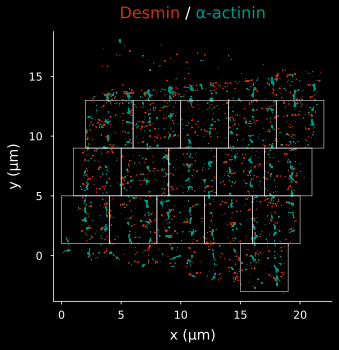

In [6]:
savepath = "../../figures/S3a"
save_panel(fig_a, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig_a)

In [ ]:
fig_b, ax_b, rendered_b = make_roi_overview(
    datadir / "results/desmin_alphaactinin_2.5um_small_aligned.csv",
    names=("desmin", "actinin"),
    x0s=(18.5, 16.5, 14.5, 14.5, 12.5, 10.5, 8.5, 6.5, 4.5, 2.5, 0.5, 4.5),
    y0s=(2.0, -2.0, -6.0, 2.0, -2.0, 2.0, -2.0, 2.0, -2.0, 2.0, -2.0, 6.0),
    **common_kwargs,
)

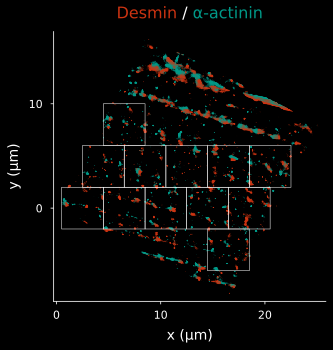

In [8]:
savepath = "../../figures/S3b"
save_panel(fig_b, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig_b)

In [ ]:
fig_c, ax_c, rendered_c = make_roi_overview(
    datadir / "results/actin_desmin_600nm_aligned.csv",
    names=("actin", "desmin"),
    x0s=(3, 7, 7, 11, 11, 11, 11, 15, 15, 15, 19, 19),
    y0s=(-2, -1.5, -5.5, -1, -5, -9, -13, -1, -5, -9, -2, -6),
    **common_kwargs,
)

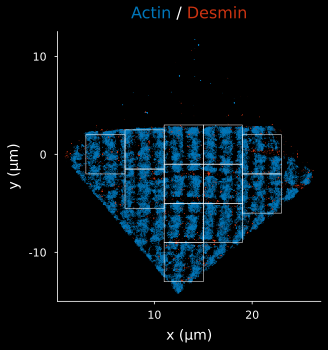

In [10]:
savepath = "../../figures/S3c"
save_panel(fig_c, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig_c)